# MatSpat — Real Data Pipeline (Tumor vs CD163+ Macrophages)

End-to-end analysis of real spatial histology data focusing on tumor–CD163+ macrophage co-localization.

> **Note:** This notebook demonstrates one example pair — tumor cells vs. CD163+ macrophages. MatSpat is not limited to this combination: you can analyse any pair of cell types (e.g., tumor vs. CD8+ T cells), merge multiple immune subtypes into a single group, or run each immune type individually to compare how different populations spatially relate to the tumor.

**Pipeline stages:**
1. **Load real CSV data** — read and inspect the raw spreadsheet; verify column names, cell type counts, and pathology label distribution
2. **Standardize** — map dataset-specific column names to MatSpat's canonical schema and encode cell types as integers
3. **ICA-based tissue rotation** — align each tissue section so the dominant tumor axis points north (+Y), making spatial trajectories orientation-invariant across samples; visualize before/after
4. **Spatial descriptors (freud)** — compute per-cell local density using freud; used here for tissue-structure visualization only (not fed into classification)
5. **Parameter sweep — Lee's L & GWPCor trajectories** — for each `(bandwidth, n_quantiles, grid_size, r_max)` combination, compute bivariate spatial correlation (Lee's L) and partial correlation (GWPCor, which removes the effect of background cell density) between tumor and CD163+ KDE surfaces, binned by quantile distance from the tumor
6. **Trajectory plots** — visualize per-image spatial trajectories for all parameter combinations
7. **Extract labels** — pull ground-truth pathology labels (e.g., CLR vs. DII) for supervised classification
8. **HMM classification** — train class-conditional Gaussian HMMs on the trajectory sequences; sweep over `n_states` and both correlation methods
9. **Results** — compare Lee's L vs. GWPCor classification performance (accuracy, balanced accuracy, F1, AUROC) and identify the best hyperparameter configuration

**GWPCor covariate:** density of all cell types *except* tumor and CD163+ macros, capturing
general tissue packing without contaminating the pair being tested.

**Before running:** place your CSV at `../data/real/` and update the **Configuration** cell.

In [2]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

%matplotlib inline
plt.rcParams["figure.dpi"] = 120

## Configuration

Set the path to your CSV and the column name mappings for your dataset.
All downstream cells use these variables — only edit here.

In [3]:
# ── Data path ──────────────────────────────────────────────────────────────
CSV_PATH = Path("../../data/real/CRC_data_cleaned_corrected.csv")

# ── Column name mappings ────────────────────────────────────────────────────
# Set each variable to the corresponding column name in your CSV.
X_COL          = "X"           # x coordinate of each cell (in tissue spatial units)
Y_COL          = "Y"           # y coordinate of each cell
CELL_TYPE_COL  = "type"        # column containing cell type labels (strings)
IMAGE_ID_COL   = "img"         # column identifying which image/tissue section each cell belongs to
PATHOLOGY_COL  = "pathology"   # column containing the per-image disease label used for classification

# ── Cell type labels ────────────────────────────────────────────────────────
# These must exactly match strings in CELL_TYPE_COL.
# Change IMMUNE_LABEL to any cell type (or combine types) you want to analyse against the tumor.
TUMOR_LABEL  = "tumor cells"    # reference cell type; used to define spatial distance bins
IMMUNE_LABEL = "CD163+ macros"  # target immune population to correlate with tumor

# ── Pipeline parameters (scalar OR list → lists trigger parameter sweeps) ──
# BANDWIDTH and R_MAX are swept together (zipped, not crossed): same index = same run.
BANDWIDTH   = [30, 60, 120, 180, 240]   # KDE bandwidth (same spatial units as coords); controls smoothing of cell-density surfaces
R_MAX       = [30, 60, 120, 180, 240]   # freud neighborhood radius for background density (keep aligned with BANDWIDTH)
N_QUANTILES = [5, 10, 20]               # number of concentric quantile rings around the tumor; more bins = finer spatial resolution
GRID_SIZE   = 100                       # KDE grid resolution (GRID_SIZE × GRID_SIZE cells); higher = more spatial detail, slower

# ── HMM parameters ──────────────────────────────────────────────────────────
N_STATES         = [2, 3, 4, 5]  # number of hidden states per class HMM to sweep over
COVARIANCE_TYPE  = "full"        # HMM emission covariance type ('full', 'diag', 'tied', 'spherical')
N_REPLICATES     = 4             # HMM restarts per fit (best log-likelihood is kept to reduce sensitivity to init)
TEST_SIZE        = 0.3           # fraction of images held out for evaluation
N_BOOTSTRAPS     = 500           # bootstrap resamples for confidence interval estimation

# ── Parallelism ──────────────────────────────────────────────────────────────
N_JOBS = 8   # number of parallel workers (set to -1 to use all cores)

# ── Normalise sweep parameters to lists ─────────────────────────────────────
def _as_list(x):
    return list(x) if isinstance(x, (list, tuple)) else [x]

BANDWIDTHS       = _as_list(BANDWIDTH)
R_MAXES          = _as_list(R_MAX)
N_QUANTILES_LIST = _as_list(N_QUANTILES)
GRID_SIZES       = _as_list(GRID_SIZE)
N_STATES_LIST    = _as_list(N_STATES)

assert len(BANDWIDTHS) == len(R_MAXES), (
    f"BANDWIDTH and R_MAX must have the same length, got {len(BANDWIDTHS)} vs {len(R_MAXES)}"
)

TARGET_PAIR = f"{TUMOR_LABEL} x {IMMUNE_LABEL}"
BW_RMAX_PAIRS = list(zip(BANDWIDTHS, R_MAXES))

print(f"Target pair      : {TARGET_PAIR}")
print(f"(bw, r_max) pairs: {BW_RMAX_PAIRS}")
print(f"N_QUANTILES      : {N_QUANTILES_LIST}")
print(f"GRID_SIZE        : {GRID_SIZES}")
print(f"N_STATES         : {N_STATES_LIST}")
print(f"N_JOBS           : {N_JOBS}")
print(f"\nTotal sweep combos : {len(BW_RMAX_PAIRS) * len(N_QUANTILES_LIST) * len(GRID_SIZES)}")
print(f"Total HMM jobs     : {len(BW_RMAX_PAIRS) * len(N_QUANTILES_LIST) * len(GRID_SIZES) * len(N_STATES_LIST) * 2} (×2 methods)")


Target pair      : tumor cells x CD163+ macros
(bw, r_max) pairs: [(30, 30), (60, 60), (120, 120), (180, 180), (240, 240)]
N_QUANTILES      : [5, 10, 20]
GRID_SIZE        : [100]
N_STATES         : [2, 3, 4, 5]
N_JOBS           : 8

Total sweep combos : 15
Total HMM jobs     : 120 (×2 methods)


## 1. Load & inspect raw data

Read the raw CSV and print basic statistics — shape, column names, number of images, cells per image, cell type distribution, and pathology label counts. This step is a sanity check to confirm the file is in the expected format before any processing.

In [6]:
assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH.resolve()}"

raw_df = pd.read_csv(CSV_PATH).dropna(how="all")
print(f"Shape: {raw_df.shape}")
print(f"Columns: {raw_df.columns.tolist()}")
raw_df.head()

Shape: (258385, 7)
Columns: ['pathology', 'patient', 'img', 'X', 'Y', 'type_orig', 'type']


,pathology,patient,img,X,Y,type_orig,type
0,1,1,1_A,77,589,granulocytes,granulocytes
1,1,1,1_A,106,826,granulocytes,granulocytes
2,1,1,1_A,107,545,granulocytes,granulocytes
3,1,1,1_A,98,564,granulocytes,granulocytes
4,1,1,1_A,217,329,granulocytes,granulocytes


In [7]:
print("Images:", raw_df[IMAGE_ID_COL].nunique())
print("\nCells per image:")
print(raw_df.groupby(IMAGE_ID_COL).size().describe())
print("\nCell type counts:")
print(raw_df[CELL_TYPE_COL].value_counts())
print("\nPathology distribution:")
print(raw_df[PATHOLOGY_COL].value_counts())

# Verify TUMOR_LABEL is present before proceeding
cell_types = raw_df[CELL_TYPE_COL].unique().tolist()
assert TUMOR_LABEL in cell_types, (
    f"TUMOR_LABEL={TUMOR_LABEL!r} not found in '{CELL_TYPE_COL}' column.\n"
    f"Available values: {sorted(cell_types)}"
)
print(f"\nTUMOR_LABEL={TUMOR_LABEL!r} ✓")

Images: 140

Cells per image:
count     140.000000
mean     1845.607143
std       795.694943
min        84.000000
25%      1299.250000
50%      1979.000000
75%      2382.000000
max      3887.000000
dtype: float64

Cell type counts:
type
tumor cells       47602
CD163+ macros     39634
smooth muscle     27817
granulocytes      22144
stroma            21126
CD8+ T cells      16675
memory CD4+ T     16661
B cells           13043
vasculature       11725
plasma cells       8510
generic immune     7077
CD68+ macros       5006
Tregs              2791
CD4+ T cells       2559
adipocytes         1811
NK cells            323
Name: count, dtype: int64

Pathology distribution:
pathology
2    147324
1    111061
Name: count, dtype: int64

TUMOR_LABEL='tumor cells' ✓


## 2. Standardize with the preprocessing module

`load_spatial_data()` maps your dataset's column names to MatSpat's canonical schema
(canonical columns: `x`, `y`, `cell_type`, `image_id`, `pathology`) and encodes cell type
strings as integers via `cell_type_map`. All downstream functions expect this schema.

In [10]:
from matspat.preprocessing import load_spatial_data
import warnings
warnings.filterwarnings('ignore')
df, cell_type_map = load_spatial_data(
    CSV_PATH,
    x_col=X_COL,
    y_col=Y_COL,
    cell_type_col=CELL_TYPE_COL,
    image_id_col=IMAGE_ID_COL,
    pathology_col=PATHOLOGY_COL,
)

print("Cell type encoding:", cell_type_map)
print(f"Shape: {df.shape}")
df.head()

Cell type encoding: {'B cells': 1, 'CD163+ macros': 2, 'CD4+ T cells': 3, 'CD68+ macros': 4, 'CD8+ T cells': 5, 'NK cells': 6, 'Tregs': 7, 'adipocytes': 8, 'generic immune': 9, 'granulocytes': 10, 'memory CD4+ T': 11, 'plasma cells': 12, 'smooth muscle': 13, 'stroma': 14, 'tumor cells': 15, 'vasculature': 16}
Shape: (244504, 7)


,cell_id,x,y,cell_type,cell_type_encoded,image_id,pathology
0,1,77.0,589.0,granulocytes,10,1_A,1
1,2,106.0,826.0,granulocytes,10,1_A,1
2,3,107.0,545.0,granulocytes,10,1_A,1
3,4,98.0,564.0,granulocytes,10,1_A,1
4,5,217.0,329.0,granulocytes,10,1_A,1


## 3. ICA rotation

`process_rotation()` fits Independent Component Analysis (ICA) on tumor cell coordinates
and rotates the entire tissue section so the dominant tumor axis points north (+Y).
This standardizes tissue orientation across samples, ensuring that spatial trajectories
(distance-from-tumor profiles computed in Step 5) are directly comparable between images
regardless of how the section was mounted on the slide.

In [11]:
from matspat.preprocessing import process_rotation

rotated_frames = []
for image_id, img_df in df.groupby("image_id"):
    rotated_frames.append(process_rotation(img_df, tumor_label=TUMOR_LABEL))

df = pd.concat(rotated_frames, ignore_index=True)

print("Added columns:", [c for c in df.columns if "rot" in c])
df[["image_id", "cell_type", "x", "y", "x_rot", "y_rot"]].head()

Added columns: ['x_rot', 'y_rot']


,image_id,cell_type,x,y,x_rot,y_rot
0,10_A,granulocytes,163.0,468.0,-450.371269,206.781818
1,10_A,granulocytes,199.0,722.0,-699.794635,266.781688
2,10_A,granulocytes,202.0,908.0,-884.665699,287.462347
3,10_A,granulocytes,224.0,908.0,-882.572829,309.362573
4,10_A,granulocytes,240.0,927.0,-899.964573,327.097489


### Before vs. after rotation

Pick one image per pathology class to visualize the ICA alignment.

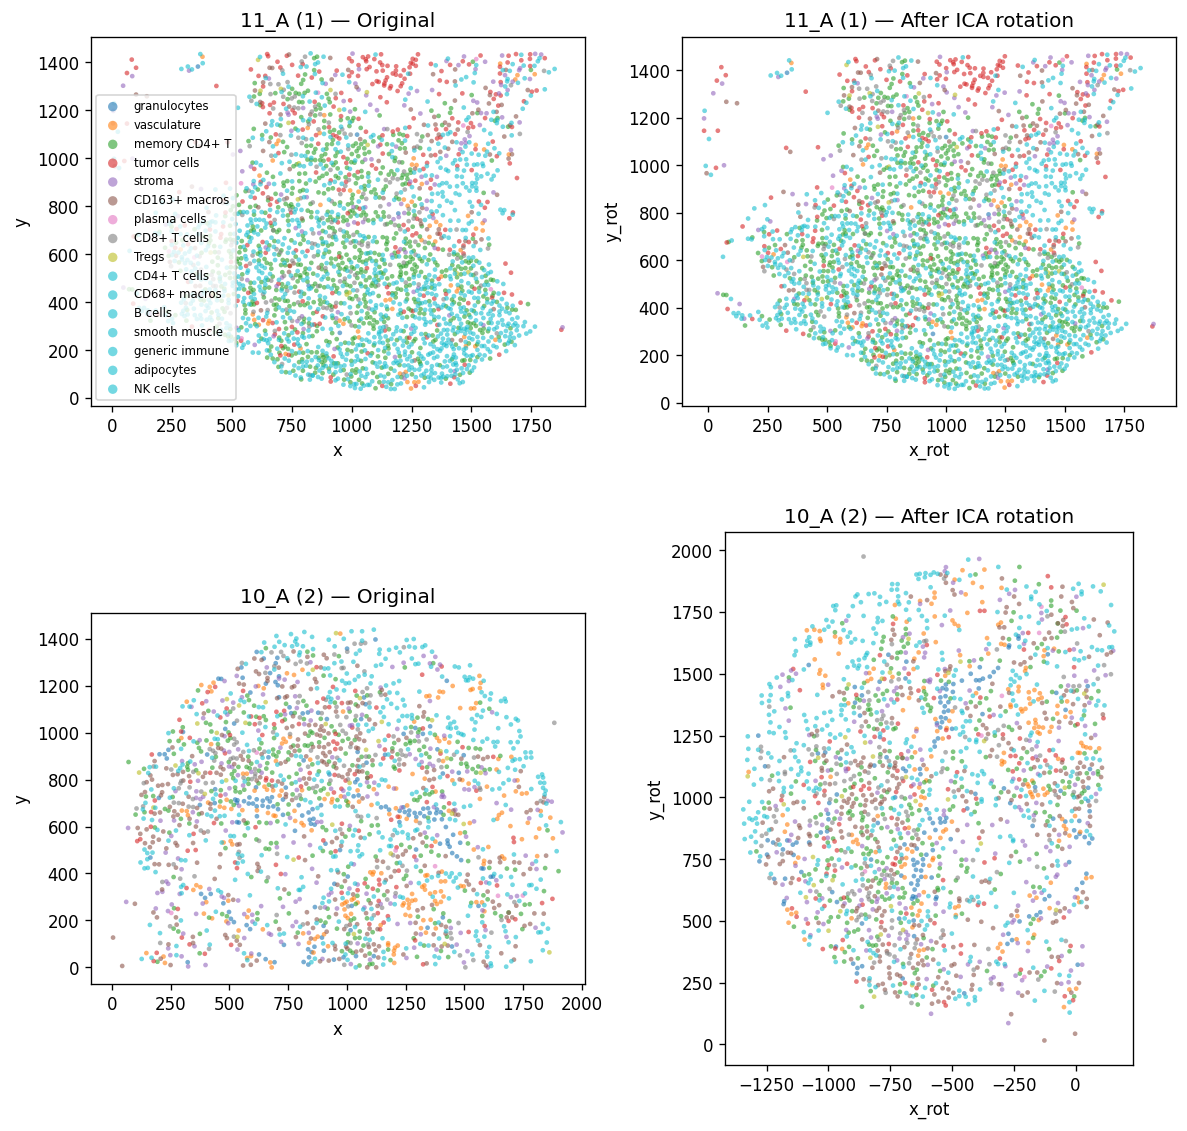

In [7]:
# Pick one image per pathology class for visualization
sample_images = (
    df[["image_id", "pathology"]]
    .drop_duplicates()
    .groupby("pathology")["image_id"]
    .first()
    .tolist()
)

cell_types = df["cell_type"].unique().tolist()
cmap = plt.get_cmap("tab10")
CELL_COLORS = {ct: cmap(i) for i, ct in enumerate(cell_types)}

fig, axes = plt.subplots(len(sample_images), 2, figsize=(10, 5 * len(sample_images)))
if len(sample_images) == 1:
    axes = axes[np.newaxis, :]

for row, img_id in enumerate(sample_images):
    img = df[df["image_id"] == img_id]
    for col, (xcol, ycol, title_suffix) in enumerate(
        [("x", "y", "Original"), ("x_rot", "y_rot", "After ICA rotation")]
    ):
        ax = axes[row, col]
        for ct, color in CELL_COLORS.items():
            mask = img["cell_type"] == ct
            ax.scatter(
                img.loc[mask, xcol],
                img.loc[mask, ycol],
                c=[color],
                label=ct,
                s=8,
                alpha=0.6,
                edgecolors="none",
            )
        pathology = img["pathology"].iloc[0]
        ax.set_title(f"{img_id} ({pathology}) — {title_suffix}")
        ax.set_xlabel(xcol)
        ax.set_ylabel(ycol)
        ax.set_aspect("equal")
        if row == 0 and col == 0:
            ax.legend(fontsize=7, markerscale=2)

fig.tight_layout()
plt.show()

## 4. Spatial descriptors (freud)

`compute_local_density()` uses [freud](https://freud.readthedocs.io/) to count the number
of neighboring cells within radius `R_MAX` for each cell — a measure of local tissue packing.

This step is used here **purely for visualization**: the density maps help you inspect
tissue structure and identify dense vs. sparse regions before committing to analysis parameters.
The GWPCor covariate in Step 5 is built separately as a KDE of background cell types
(all types except tumor and CD163+ macros), not from these per-cell counts.

In [8]:
from joblib import Parallel, delayed
from matspat.descriptors import compute_local_density

# Descriptors use rotated coordinates
desc_df = df.rename(columns={"x": "x_orig", "y": "y_orig", "x_rot": "x", "y_rot": "y"})

BG_TYPES_OVERRIDE = ["stroma", "vasculature", "smooth muscle", "adipocytes"]  
# Background cell types: everything except the pair being tested
#BG_TYPES = sorted(ct for ct in desc_df["cell_type"].unique()
  #                if ct not in [TUMOR_LABEL, IMMUNE_LABEL])

BG_TYPES = BG_TYPES_OVERRIDE
print(f"Background cell types ({len(BG_TYPES)}): {BG_TYPES}")

# Compute freud background density at each r_max (used as GWPCor covariate)
def _bg_density_for_rmax(r_max):
    return r_max, compute_local_density(desc_df, r_max=r_max, include_cell_types=BG_TYPES)

bg_density_results = Parallel(n_jobs=N_JOBS, backend="loky", verbose=1)(
    delayed(_bg_density_for_rmax)(r_max) for r_max in R_MAXES
)
bg_density_by_rmax = dict(bg_density_results)

for r_max in R_MAXES:
    print(f"  r_max={r_max:<5}  bg_density rows={len(bg_density_by_rmax[r_max])}")
print("\nDone.")

Background cell types (4): ['stroma', 'vasculature', 'smooth muscle', 'adipocytes']


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 out of   5 | elapsed:    1.4s remaining:    2.0s


  r_max=30     bg_density rows=62479
  r_max=60     bg_density rows=62479
  r_max=120    bg_density rows=62479
  r_max=180    bg_density rows=62479
  r_max=240    bg_density rows=62479

Done.


[Parallel(n_jobs=8)]: Done   5 out of   5 | elapsed:    2.3s finished


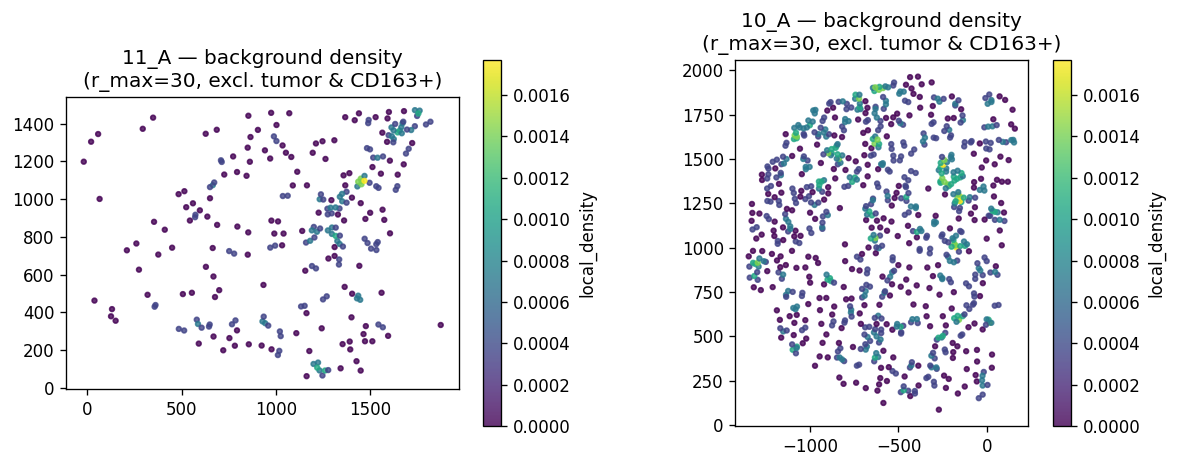

In [9]:
# Visualise background local density at the first r_max across sample images
r_max_vis = R_MAXES[0]
density_vis = bg_density_by_rmax[r_max_vis]

fig, axes = plt.subplots(1, len(sample_images), figsize=(5 * len(sample_images), 4))
if len(sample_images) == 1:
    axes = [axes]

for ax, img_id in zip(axes, sample_images):
    img_density = density_vis[density_vis["image_id"] == img_id]
    img_coords  = desc_df[desc_df["image_id"] == img_id]
    merged = img_coords[["cell_id", "x", "y"]].merge(
        img_density[["cell_id", "local_density"]], on="cell_id"
    )
    sc = ax.scatter(merged["x"], merged["y"], c=merged["local_density"],
                    s=8, cmap="viridis", alpha=0.8)
    ax.set_title(f"{img_id} — background density\n(r_max={r_max_vis}, excl. tumor & CD163+)")
    ax.set_aspect("equal")
    plt.colorbar(sc, ax=ax, label="local_density")

fig.tight_layout()
plt.show()

## 5. Parameter sweep — Tumor × CD163+ trajectories (Lee's L & GWPCor)

For every `(bandwidth, n_quantiles, grid_size, r_max)` combination:

- **Lee's L** — bivariate spatial correlation between the tumor KDE surface and the CD163+
  KDE surface, computed at each quantile ring around the tumor. A positive value indicates
  co-localization; negative indicates exclusion.
- **GWPCor** — geographically weighted partial correlation: same as Lee's L, but after
  regressing out the KDE of all *other* cell types (background tissue packing) from both
  surfaces. This isolates tumor–CD163+ specific co-localization, removing spurious
  correlation driven by regions that are globally dense with cells.

The result is a trajectory — a vector of correlation values indexed by quantile distance
from the tumor — for each image and parameter combination.

In [10]:
from itertools import product

import numpy as np
from sklearn.neighbors import KernelDensity

from matspat.density import build_grid, get_marginal_quantile_masks
from matspat.interactions import compute_pairwise_trajectories, gwpcor_sequence, interpolate_to_grid


def _gwpcor_one_image(image_id, img_df, bg_density_df, bw, nq, gs, tumor_label, immune_label):
    """GWPCor for one image: tumor vs immune_label, controlling for freud background density."""
    from sklearn.neighbors import KernelDensity
    from matspat.density import build_grid, get_marginal_quantile_masks
    from matspat.interactions import gwpcor_sequence, interpolate_to_grid

    tumor_coords  = img_df.loc[img_df["cell_type"] == tumor_label,  ["x_rot", "y_rot"]].values
    immune_coords = img_df.loc[img_df["cell_type"] == immune_label, ["x_rot", "y_rot"]].values

    if tumor_coords.shape[0] < 2 or immune_coords.shape[0] < 2:
        return []

    all_coords = img_df[["x_rot", "y_rot"]].values
    _xs, _ys, grid_pts = build_grid(all_coords, gs)

    tumor_flat  = np.exp(KernelDensity(bandwidth=bw).fit(tumor_coords).score_samples(grid_pts))
    immune_flat = np.exp(KernelDensity(bandwidth=bw).fit(immune_coords).score_samples(grid_pts))

    # Covariate: freud background density interpolated onto the KDE grid
    img_bg = bg_density_df[bg_density_df["image_id"] == image_id]
    img_coords = desc_df[desc_df["image_id"] == image_id]
    merged_bg = img_coords[["cell_id", "x", "y"]].merge(img_bg[["cell_id", "local_density"]], on="cell_id")
    if len(merged_bg) < 2:
        return []
    z_full = interpolate_to_grid(merged_bg[["x", "y"]].values, merged_bg["local_density"].values, grid_pts)

    masks_list = [get_marginal_quantile_masks(tumor_flat.reshape(gs, gs), nq)[i] for i in range(nq)]
    pair     = f"{tumor_label} x {immune_label}"
    gwp_vals = gwpcor_sequence(tumor_flat, immune_flat, z_full, grid_pts, bw, masks_list)

    return [
        {"image_id": image_id, "immune_pair": pair, "quantile_bin": q, "gwpcor": gval}
        for q, gval in enumerate(gwp_vals)
    ]


def _compute_sweep_combo(bw, nq, gs, r_max):
    """Worker: Lee's L + GWPCor for one (bw, nq, gs, r_max) combo."""
    import pandas as pd
    from joblib import Parallel, delayed
    from matspat.interactions import compute_pairwise_trajectories

    traj = compute_pairwise_trajectories(
        df, tumor_label=TUMOR_LABEL, bandwidth=bw, n_quantiles=nq,
        quantile_method="marginal", grid_size=gs,
    )
    traj = traj[traj["immune_pair"] == TARGET_PAIR].copy()

    bg_density_df = bg_density_by_rmax[r_max]
    image_rows = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_gwpcor_one_image)(image_id, img_df, bg_density_df, bw, nq, gs, TUMOR_LABEL, IMMUNE_LABEL)
        for image_id, img_df in df.groupby("image_id")
    )
    gwpcor_rows = [row for rows in image_rows for row in rows]

    return (bw, nq, gs, r_max), {"lees_l": traj, "gwpcor": pd.DataFrame(gwpcor_rows)}


combos = [(bw, nq, gs, r_max) for (bw, r_max), nq, gs in product(BW_RMAX_PAIRS, N_QUANTILES_LIST, GRID_SIZES)]
print(f"Running {len(combos)} parameter combos …")

from joblib import Parallel, delayed

sweep_list = Parallel(n_jobs=N_JOBS, backend="loky", verbose=5)(
    delayed(_compute_sweep_combo)(bw, nq, gs, r_max) for bw, nq, gs, r_max in combos
)

sweep_results = dict(sweep_list)
print("\nSweep complete.")
for (bw, nq, gs, r_max), data in sweep_results.items():
    print(f"  bw={bw:<4} r={r_max:<4} nq={nq:<3} gs={gs:<4}  "
          f"lees_l={len(data['lees_l'])}  gwpcor={len(data['gwpcor'])}")

Running 15 parameter combos …


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/1662917134.py:52: UserWarning: Image '19_B': 1 tumor cells (< min_tumor_cells=2), skipping.
/tmp/ipykernel_2854/166291713


Sweep complete.
  bw=30   r=30   nq=5   gs=100   lees_l=695  gwpcor=695
  bw=30   r=30   nq=10  gs=100   lees_l=1390  gwpcor=1390
  bw=30   r=30   nq=20  gs=100   lees_l=2780  gwpcor=2780
  bw=60   r=60   nq=5   gs=100   lees_l=695  gwpcor=695
  bw=60   r=60   nq=10  gs=100   lees_l=1390  gwpcor=1390
  bw=60   r=60   nq=20  gs=100   lees_l=2780  gwpcor=2780
  bw=120  r=120  nq=5   gs=100   lees_l=695  gwpcor=695
  bw=120  r=120  nq=10  gs=100   lees_l=1390  gwpcor=1390
  bw=120  r=120  nq=20  gs=100   lees_l=2780  gwpcor=2780
  bw=180  r=180  nq=5   gs=100   lees_l=695  gwpcor=695
  bw=180  r=180  nq=10  gs=100   lees_l=1390  gwpcor=1390
  bw=180  r=180  nq=20  gs=100   lees_l=2780  gwpcor=2780
  bw=240  r=240  nq=5   gs=100   lees_l=695  gwpcor=695
  bw=240  r=240  nq=10  gs=100   lees_l=1390  gwpcor=1390
  bw=240  r=240  nq=20  gs=100   lees_l=2780  gwpcor=2780


### Trajectory plots — all parameter combinations

One figure per `(bw, nq, gs)` combo saved to `../../figures/<tag>/trajectory_comparison.png`.
Each line is one image; colors distinguish pathology class (e.g., CLR vs. DII).
Use these plots to assess how well the two classes separate along the trajectory
before running classification.

In [11]:
image_disease = (
    raw_df[[IMAGE_ID_COL, PATHOLOGY_COL]]
    .drop_duplicates()
    .set_index(IMAGE_ID_COL)[PATHOLOGY_COL]
)

styles = ["-o", "--s", "-.^", ":D"]
fig_root = Path("../../figures")

for (bw, nq, gs, r_max), data in sweep_results.items():
    _traj = data["lees_l"].copy()
    _gwp  = data["gwpcor"].copy()

    _traj["disease"] = _traj["image_id"].map(image_disease)
    _gwp["disease"]  = _gwp["image_id"].map(image_disease)

    disease_classes = sorted(_traj["disease"].dropna().unique())

    fig, axes = plt.subplots(2, 1, figsize=(5, 7), sharey=True)

    ax = axes[0]
    for disease, style in zip(disease_classes, styles):
        sub = _traj[_traj["disease"] == disease]
        mean_traj = sub.groupby("quantile_bin")["lees_L"].mean()
        ax.plot(mean_traj.index, mean_traj.values, style, label=disease, markersize=5)
    ax.set_title(f"{TARGET_PAIR}\nbw={bw}, nq={nq}, r={r_max}")
    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    ax.set_ylabel("Lee's L")
    ax.legend(fontsize=8)

    ax = axes[1]
    for disease, style in zip(disease_classes, styles):
        sub = _gwp[_gwp["disease"] == disease]
        mean_traj = sub.groupby("quantile_bin")["gwpcor"].mean()
        ax.plot(mean_traj.index, mean_traj.values, style, label=disease, markersize=5)
    ax.set_xlabel("Quantile bin (low → high tumor density)")
    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    ax.set_ylabel("GWPCor")

    fig.suptitle("Lee's L (top) vs GWPCor (bottom) — mean per disease class", fontsize=11, y=1.01)
    fig.tight_layout()

    tag = f"bw{int(bw)}_nq{int(nq)}_gs{int(gs)}_r{int(r_max)}"
    out_dir = fig_root / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / "trajectory_comparison.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

print(f"Saved {len(sweep_results)} figures to {fig_root.resolve()}")

Saved 15 figures to /home/npkamath/MatSpat/MatSpat/figures


In [12]:
  # Use one representative combo                                                                           
  diag_key = next(iter(sweep_results))
  bw, nq, gs, r_max = diag_key                                                                             
  data = sweep_results[diag_key]                                                                           
  print(f"Diagnostic on combo: bw={bw}, nq={nq}, gs={gs}, r_max={r_max}\n")                                
                                                                                                           
  _traj = data["lees_l"].copy()                                                                            
  _gwp  = data["gwpcor"].copy()                                                                            
  _traj["disease"] = _traj["image_id"].map(image_disease)                                                  
  _gwp["disease"]  = _gwp["image_id"].map(image_disease)                                                   
                                                                                                           
  # ── 1. NaN rate in GWPCor before fill ────────────────────────────────────────                          
  nan_rate = _gwp.groupby("quantile_bin")["gwpcor"].apply(lambda s: s.isna().mean())                       
  print("GWPCor NaN rate per quantile bin:")                                                               
  print(nan_rate.round(3).to_string())
                                                                                                           
  # ── 2. Value ranges ───────────────────────────────────────────────────────────
  print(f"\nLee's L  — min={_traj['lees_L'].min():.3f}  max={_traj['lees_L'].max():.3f}  "                 
        f"std={_traj['lees_L'].std():.3f}")                                                                
  print(f"GWPCor   — min={_gwp['gwpcor'].min():.3f}  max={_gwp['gwpcor'].max():.3f}  "                     
        f"std={_gwp['gwpcor'].std():.3f}")                                                                 
                                                                                                           
  # ── 3. Within-class std per quantile bin ─────────────────────────────────────                          
  print("\nWithin-class std per bin (lower = more separable per image):")                                  
  for method_name, df_, col in [("Lee's L", _traj, "lees_L"), ("GWPCor", _gwp, "gwpcor")]:                 
      within_std = df_.groupby(["disease", "quantile_bin"])[col].std().groupby("quantile_bin").mean()      
      print(f"  {method_name}: {within_std.round(3).values}")                                              
                                                                                                           
  # ── 4. Per-image trajectory variance (how spread are images within each class) ─                        
  print("\nPer-image mean trajectory std across images (within class):")
  for method_name, df_, col in [("Lee's L", _traj, "lees_L"), ("GWPCor", _gwp, "gwpcor")]:                 
      img_means = df_.groupby(["disease", "image_id"])[col].mean()                                         
      within_class_spread = img_means.groupby("disease").std()                                             
      print(f"  {method_name}:")                                                                           
      print(within_class_spread.round(3).to_string(header=False))                                        
                                                                                                           
  # ── 5. Between-class separation (mean diff / pooled std) ─────────────────────                          
  print("\nBetween-class separation (Cohen's d on mean trajectory per image):")                            
  for method_name, df_, col in [("Lee's L", _traj, "lees_L"), ("GWPCor", _gwp, "gwpcor")]:                 
      img_means = df_.groupby(["image_id"])[col].mean()                                                  
      img_means.index = pd.Index([str(i) for i in img_means.index])                                        
      classes = sorted(_traj["disease"].dropna().unique())                                                 
      if len(classes) == 2:                                                                                
          g0 = _traj[_traj["disease"] == classes[0]]["image_id"].unique()                                  
          g1 = _traj[_traj["disease"] == classes[1]]["image_id"].unique()                                  
          v0 = df_[df_["image_id"].isin(g0)].groupby("image_id")[col].mean()                             
          v1 = df_[df_["image_id"].isin(g1)].groupby("image_id")[col].mean()                               
          pooled_std = np.sqrt((v0.std()**2 + v1.std()**2) / 2)                                          
          d = abs(v0.mean() - v1.mean()) / (pooled_std + 1e-9)                                             
          print(f"  {method_name}: d={d:.3f}  ({classes[0]} μ={v0.mean():.3f} vs {classes[1]} μ={v1.mean():.3f})")  

Diagnostic on combo: bw=30, nq=5, gs=100, r_max=30

GWPCor NaN rate per quantile bin:
quantile_bin
0    0.036
1    0.007
2    0.007
3    0.007
4    0.007

Lee's L  — min=-0.620  max=0.551  std=0.140
GWPCor   — min=-0.600  max=0.540  std=0.138

Within-class std per bin (lower = more separable per image):
  Lee's L: [0.107 0.08  0.059 0.077 0.155]
  GWPCor: [0.105 0.08  0.06  0.078 0.152]

Per-image mean trajectory std across images (within class):
  Lee's L:
1    0.044
2    0.046
  GWPCor:
1    0.044
2    0.046

Between-class separation (Cohen's d on mean trajectory per image):
  Lee's L: d=0.268  (1 μ=0.021 vs 2 μ=0.009)
  GWPCor: d=0.305  (1 μ=0.022 vs 2 μ=0.008)


## 6. Extract labels

Map each image to its ground-truth pathology class. `extract_labels()` returns a
`{image_id: label}` dict that is used as supervision for HMM training and evaluation.
The class distribution is printed here as a check — highly imbalanced datasets may
warrant stratified splitting or adjusted metrics.

In [13]:
from matspat.classification import build_sequences, extract_labels, split_and_classify

label_df = df[["image_id", "pathology"]].drop_duplicates().rename(columns={"pathology": "label"})
labels   = extract_labels(label_df)
print("Labels:", labels)
print("\nClass distribution:", pd.Series(labels).value_counts().to_dict())

Labels: {'10_A': 1, '10_B': 1, '11_A': 0, '11_B': 0, '12_A': 0, '12_B': 0, '13_A': 1, '13_B': 1, '14_A': 1, '14_B': 1, '15_A': 1, '15_B': 1, '16_A': 1, '16_B': 1, '17_A': 1, '17_B': 1, '18_A': 1, '18_B': 1, '19_A': 0, '19_B': 0, '1_A': 0, '1_B': 0, '20_A': 0, '20_B': 0, '21_A': 0, '21_B': 0, '22_A': 0, '22_B': 0, '23_A': 0, '23_B': 0, '24_A': 0, '24_B': 0, '25_A': 0, '25_B': 0, '26_A': 0, '26_B': 0, '27_A': 1, '27_B': 1, '28_A': 1, '28_B': 1, '29_A': 1, '29_B': 1, '2_A': 0, '2_B': 0, '30_A': 1, '30_B': 1, '31_A': 1, '31_B': 1, '32_A': 1, '32_B': 1, '33_A': 0, '33_B': 0, '34_A': 0, '34_B': 0, '35_A': 1, '35_B': 1, '36_A': 1, '36_B': 1, '37_A': 0, '37_B': 0, '38_A': 0, '38_B': 0, '39_A': 0, '39_B': 0, '3_A': 1, '3_B': 1, '40_A': 0, '40_B': 0, '41_A': 0, '41_B': 0, '42_A': 0, '42_B': 0, '43_A': 1, '43_B': 1, '44_A': 1, '44_B': 1, '45_A': 1, '45_B': 1, '46_A': 1, '46_B': 1, '47_A': 0, '47_B': 0, '48_A': 0, '48_B': 0, '49_A': 1, '49_B': 1, '4_A': 1, '4_B': 1, '50_A': 1, '50_B': 1, '51_A': 1

## 7. HMM classification sweep — Lee's L vs GWPCor

For each `(bandwidth, n_quantiles, grid_size, r_max, n_states)` combination, a pair of
class-conditional Gaussian HMMs is trained — one per pathology class — on the tumor × CD163+
trajectory sequences from both Lee's L and GWPCor. Classification assigns a new image to
the class whose HMM assigns higher log-likelihood to its trajectory.

Results (accuracy, balanced accuracy, F1, AUROC) are collected across all combinations
for the comparison in Step 8.

In [14]:
from joblib import Parallel, delayed
from matspat.classification import build_sequences, extract_labels, split_and_classify

_METHOD_KEY = {"Lee's L": "lees_l", "GWPCor": "gwpcor"}
_VALUE_COL  = {"Lee's L": "lees_L",  "GWPCor": "gwpcor"}


def _run_hmm(sweep_key, data, ns, method_name, labels, test_size, cov_type, n_rep, n_boot):
    from matspat.classification import build_sequences, split_and_classify

    seqs, _ = build_sequences(data[_METHOD_KEY[method_name]], value_col=_VALUE_COL[method_name])
    try:
        result = split_and_classify(
            seqs, labels,
            test_size=test_size, n_states=ns,
            covariance_type=cov_type, n_replicates=n_rep, n_bootstraps=n_boot,
        )
        bw, nq, gs, r_max = sweep_key
        row = {"bandwidth": bw, "n_quantiles": nq, "grid_size": gs, "r_max": r_max,
               "n_states": ns, "method": method_name}
        row.update(result.metrics)
        return row
    except Exception:
        return None


hmm_jobs = [
    (sweep_key, data, ns, method_name, labels, TEST_SIZE, COVARIANCE_TYPE, N_REPLICATES, N_BOOTSTRAPS)
    for sweep_key, data in sweep_results.items()
    for ns in N_STATES_LIST
    for method_name in ["Lee's L", "GWPCor"]
]

print(f"Running {len(hmm_jobs)} HMM jobs …")

hmm_rows = Parallel(n_jobs=N_JOBS, backend="loky", verbose=5)(
    delayed(_run_hmm)(*job) for job in hmm_jobs
)

hmm_results_df = pd.DataFrame([r for r in hmm_rows if r is not None])
print(f"\nTotal results: {len(hmm_results_df)}")
hmm_results_df

Running 90 HMM jobs …


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
Model is not converging.  Current: 602.7484687262138 is not greater than 602.7485323968706. Delta is -6.367065680024098e-05
Model is not converging.  Current: 606.6770436914517 is not greater than 606.6770615381974. Delta is -1.7846745777205797e-05
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    5.2s
Model is not converging.  Current: 260.03360917233 is not greater than 260.03419158192014. Delta is -0.0005824095901516557
Model is not converging.  Current: 258.49089896423465 is not greater than 258.49732445392794. Delta is -0.006425489693299369
Model is not converging.  Current: 258.16040012412174 is not greater than 258.1616269301257. Delta is -0.0012268060039559714
Model is not converging.  Current: 260.031008786537 is not greater than 260.031024994569. Delta is -1.6208032036502118e-05
Model is not converging.  Current: 279.5156622309097 is not greater than 279.51579240938696. Delta is -0.00013017847726


Total results: 81


[Parallel(n_jobs=8)]: Done  90 out of  90 | elapsed:  1.9min finished


,bandwidth,n_quantiles,grid_size,r_max,n_states,method,accuracy,balanced_accuracy,f1_score,sensitivity,auroc
0,30,5,100,30,2,Lee's L,0.642857,0.646154,0.642857,0.600000,0.635897
1,30,5,100,30,3,Lee's L,0.571429,0.574359,0.571429,0.533333,0.687179
2,30,5,100,30,4,Lee's L,0.642857,0.646154,0.642857,0.600000,0.615385
3,30,10,100,30,2,Lee's L,0.571429,0.569231,0.600000,0.600000,0.502564
4,30,10,100,30,3,Lee's L,0.464286,0.474359,0.400000,0.333333,0.430769
...,...,...,...,...,...,...,...,...,...,...,...
76,240,20,100,240,2,GWPCor,0.714286,0.717949,0.714286,0.666667,0.764103
77,240,20,100,240,3,Lee's L,0.642857,0.630769,0.705882,0.800000,0.682051
78,240,20,100,240,3,GWPCor,0.678571,0.674359,0.709677,0.733333,0.707692
79,240,20,100,240,4,Lee's L,0.500000,0.487179,0.588235,0.666667,0.635897


## 8. Results — Lee's L vs GWPCor comparison

Summarize classification performance across all hyperparameter configurations.
The table shows the best accuracy, balanced accuracy, F1, and AUROC achieved per method.
Scatter and bar plots contrast Lee's L vs. GWPCor AUROC across configurations, making
it easy to see whether partial correlation (GWPCor) improves discrimination over raw
spatial correlation (Lee's L), and which hyperparameter settings drive the best results.

In [15]:
print("Best results per method (by AUROC):")
print(
    hmm_results_df.groupby("method")[["accuracy", "balanced_accuracy", "f1_score", "auroc"]]
    .max()
    .round(3)
    .to_string()
)

print("\nTop 10 configurations by AUROC:")
print(
    hmm_results_df.sort_values("auroc", ascending=False)
    .head(10)[["method", "bandwidth", "r_max", "n_quantiles", "n_states", "auroc", "balanced_accuracy", "f1_score"]]
    .to_string(index=False)
)

Best results per method (by AUROC):
         accuracy  balanced_accuracy  f1_score  auroc
method                                               
GWPCor      0.714              0.723     0.714  0.764
Lee's L     0.714              0.713     0.733  0.728

Top 10 configurations by AUROC:
 method  bandwidth  r_max  n_quantiles  n_states    auroc  balanced_accuracy  f1_score
 GWPCor        240    240           20         2 0.764103           0.717949  0.714286
Lee's L        180    180            5         4 0.728205           0.712821  0.733333
Lee's L        180    180            5         3 0.712821           0.674359  0.709677
 GWPCor        240    240           20         3 0.707692           0.674359  0.709677
Lee's L         30     30            5         3 0.687179           0.574359  0.571429
 GWPCor         60     60            5         2 0.687179           0.646154  0.642857
Lee's L         60     60            5         2 0.687179           0.607692  0.620690
Lee's L        120 

/tmp/ipykernel_2854/2433330212.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([plot_df.loc[plot_df["label"] == g, "auroc"].values for g in groups],


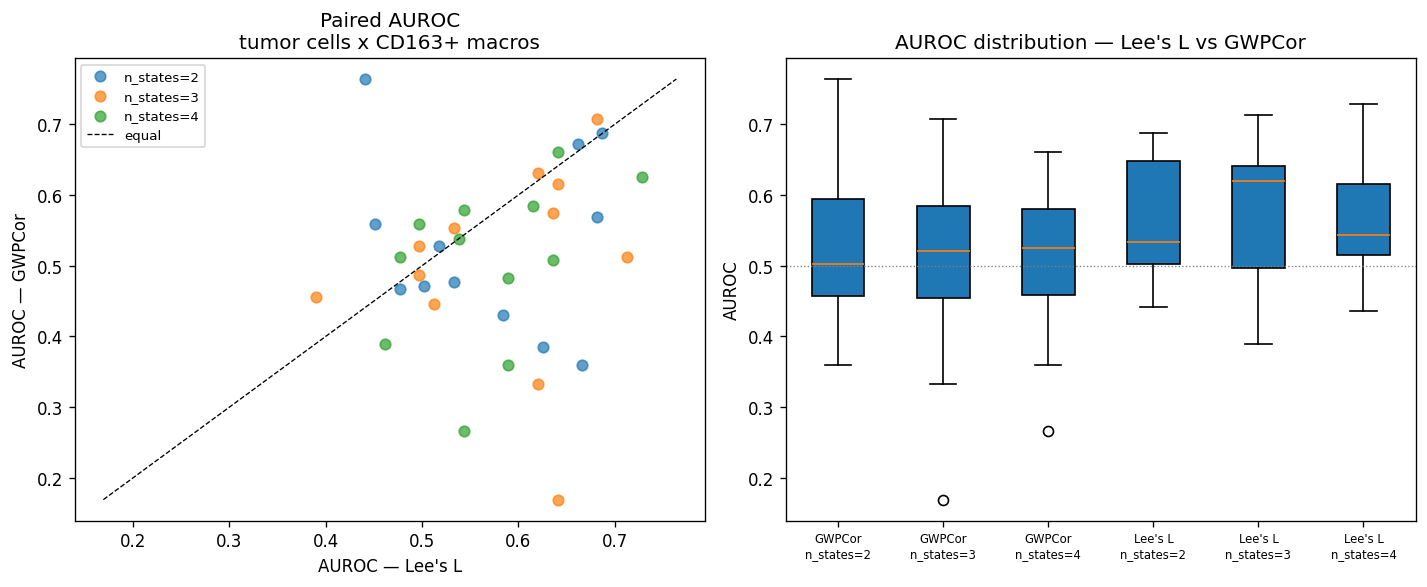

In [16]:
pivot = hmm_results_df.pivot_table(
    index=["bandwidth", "r_max", "n_quantiles", "grid_size", "n_states"],
    columns="method",
    values="auroc",
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
for ns in N_STATES_LIST:
    sub = pivot[pivot["n_states"] == ns]
    ax.scatter(sub["Lee's L"], sub["GWPCor"], label=f"n_states={ns}", alpha=0.7, s=40)
lo = pivot[["Lee's L", "GWPCor"]].min().min()
hi = pivot[["Lee's L", "GWPCor"]].max().max()
ax.plot([lo, hi], [lo, hi], "k--", linewidth=0.8, label="equal")
ax.set_xlabel("AUROC — Lee's L")
ax.set_ylabel("AUROC — GWPCor")
ax.set_title(f"Paired AUROC\n{TARGET_PAIR}")
ax.legend(fontsize=8)

ax = axes[1]
plot_df = hmm_results_df.copy()
plot_df["label"] = plot_df["method"] + "\nn_states=" + plot_df["n_states"].astype(str)
groups = sorted(plot_df["label"].unique())
ax.boxplot([plot_df.loc[plot_df["label"] == g, "auroc"].values for g in groups],
           labels=groups, patch_artist=True)
ax.set_ylabel("AUROC")
ax.set_title("AUROC distribution — Lee's L vs GWPCor")
ax.tick_params(axis="x", labelsize=7)
ax.axhline(0.5, color="grey", linewidth=0.8, linestyle=":")

fig.tight_layout()
plt.show()